### News

**Read our [Gemma 3 blog](https://unsloth.ai/blog/gemma3) for what's new in Unsloth and our [Reasoning blog](https://unsloth.ai/blog/r1-reasoning) on how to train reasoning models.**

Visit our docs for all our [model uploads](https://docs.unsloth.ai/get-started/all-our-models) and [notebooks](https://docs.unsloth.ai/get-started/unsloth-notebooks).


### Installation

In [ ]:
%%capture
%pip install -U unsloth
%pip install pybase64

# Original installation commands (legacy; retained for reference):
# %%capture
# import os
# if "COLAB_" not in "".join(os.environ.keys()):
#     !pip install unsloth vllm
# else:
    # [NOTE] Do the below ONLY in Colab! Use [[pip install unsloth vllm]]
#     !pip install --no-deps unsloth vllm
# Install latest Hugging Face for Gemma-3!
# !pip install --no-deps git+https://github.com/huggingface/transformers@v4.49.0-Gemma-3
# !pip install bitsandbytes
# !pip install unsloth_zoo
# !pip install msgspec
# !pip install blake3
# !pip install gguf
# !pip install networkx==2.8.8 --force-reinstall

In [ ]:
#@title Colab Extra Install { display-mode: "form" }
# %%capture
# import os
# if "COLAB_" not in "".join(os.environ.keys()):
#     !pip install unsloth vllm
# else:
#     !pip install --no-deps unsloth vllm
    # [NOTE] Do the below ONLY in Colab! Use [[pip install unsloth vllm]]
    # Skip restarting message in Colab
#     import sys, re, requests; modules = list(sys.modules.keys())
#     for x in modules: sys.modules.pop(x) if "PIL" in x or "google" in x else None
#     !pip install --no-deps bitsandbytes accelerate xformers==0.0.29.post3 peft trl triton cut_cross_entropy unsloth_zoo
#     !pip install sentencepiece protobuf datasets huggingface_hub hf_transfer

    # vLLM requirements - vLLM breaks Colab due to reinstalling numpy
#     f = requests.get("https://raw.githubusercontent.com/vllm-project/vllm/refs/heads/main/requirements/common.txt").content
#     with open("vllm_requirements.txt", "wb") as file:
#         file.write(re.sub(rb"(transformers|numpy|xformers)[^\n]{1,}\n", b"", f))
#     !pip install -r vllm_requirements.txt

# Dependencies are installed in the previous cell; no extra vLLM install is needed for native inference.
import importlib.metadata as metadata
for package in ["unsloth", "transformers", "trl"]:
    print(package, metadata.version(package))

unsloth 2026.11.12
transformers 5.17.0
trl 1.15.0


### Unsloth

`FastModel` supports loading nearly any model now! This includes Vision and Text models!

In [ ]:
from unsloth import FastModel
import torch

fourbit_models = [
    # 4bit dynamic quants for superior accuracy and low memory use
    "unsloth/gemma-3-1b-it-unsloth-bnb-4bit",
    "unsloth/gemma-3-4b-it-unsloth-bnb-4bit",
    "unsloth/gemma-3-12b-it-unsloth-bnb-4bit",
    "unsloth/gemma-3-27b-it-unsloth-bnb-4bit",

    # Other popular models!
    "unsloth/Llama-3.1-8B",
    "unsloth/Llama-3.2-3B",
    "unsloth/Llama-3.3-70B",
    "unsloth/mistral-7b-instruct-v0.3",
    "unsloth/Phi-4",
] # More models at https://huggingface.co/unsloth

model, tokenizer = FastModel.from_pretrained(
    model_name = "unsloth/gemma-3-4b-it",
    max_seq_length = 2048, # Choose any for long context!
    load_in_4bit = True,  # 4 bit quantization to reduce memory
    load_in_8bit = False, # [NEW!] A bit more accurate, uses 2x memory
    full_finetuning = False, # [NEW!] We have full finetuning now!
    # token = "hf_...", # use one if using gated models
)

/usr/local/lib/python3.13/dist-packages/unsloth/__init__.py:2315: UserWarning: WARNING: Unsloth should be imported before [transformers, peft] to ensure all optimizations are applied. Your code may run slower or encounter memory issues without these optimizations.

Please restructure your imports with 'import unsloth' at the top of your file.
  from ._gpu_init import *


Unsloth: xformers does not load with torch 2.14.1+cu130, using PyTorch attention (UNSLOTH_ENABLE_LOGGING=1 for the fix).
🦥 Unsloth Zoo will now patch everything to make training faster!
==((====))==  Unsloth 2026.11.12: Fast Gemma3 patching. Transformers: 5.17.0. vLLM: 0.34.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.14.1+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.8.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: Using float16 precision for gemma3 won't work! Using float32.


Loading weights:   0%|          | 0/883 [00:00<?, ?it/s]

Skipping model.vision_tower.encoder.layers.0.self_attn.k_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.v_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.q_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.self_attn.out_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.0.mlp.fc1: no quant_state found
Skipping model.vision_tower.encoder.layers.0.mlp.fc2: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.k_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.v_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.q_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.self_attn.out_proj: no quant_state found
Skipping model.vision_tower.encoder.layers.1.mlp.fc1: no quant_state found
Skipping model.vision_tower.encoder.layers.1.mlp.fc2: no quant_state found
Skipping model.vision_to

We now add LoRA adapters so we only need to update a small amount of parameters!

In [ ]:
model = FastModel.get_peft_model(
    model,
    finetune_vision_layers     = False, # Turn off for just text!
    finetune_language_layers   = True,  # Should leave on!
    finetune_attention_modules = True,  # Attention good for GRPO
    finetune_mlp_modules       = True,  # SHould leave on always!

    r = 8,           # Larger = higher accuracy, but might overfit
    lora_alpha = 8,  # Recommended alpha == r at least
    lora_dropout = 0,
    bias = "none",
    random_state = 3407,
)

<a name="Data"></a>
### Data Prep
We now use the `Gemma-3` format for conversation style finetunes. We use [Maxime Labonne's FineTome-100k](https://huggingface.co/datasets/mlabonne/FineTome-100k) dataset in ShareGPT style. Gemma-3 renders multi turn conversations like below:

```
<bos><start_of_turn>user
Hello!<end_of_turn>
<start_of_turn>model
Hey there!<end_of_turn>
```

We use our `get_chat_template` function to get the correct chat template. We support `zephyr, chatml, mistral, llama, alpaca, vicuna, vicuna_old, phi3, llama3, phi4, qwen2.5, gemma3` and more.

In [ ]:
from unsloth.chat_templates import get_chat_template
tokenizer = get_chat_template(
    tokenizer,
    chat_template = "gemma-3",
)

In [ ]:
from datasets import load_dataset
from google.colab import drive
from pathlib import Path
drive.mount("/content/drive")
DATA_PATH = Path("/content/drive/My Drive/ColabNotebooks/I5/ADV/data_kh.csv")
assert DATA_PATH.is_file(), f"Missing file: {DATA_PATH}"
dataset = load_dataset("csv", data_files=str(DATA_PATH))

Mounted at /content/drive


Generating train split: 0 examples [00:00, ? examples/s]

In [ ]:
dataset['train']['input'][0]

'តើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា ជាអ្វី'

In [ ]:
def formatting_prompts_func(examples):
    instructions = examples["input"]
    outputs      = examples["output"]
    texts = []
    for instruction, output in zip(instructions, outputs):
      messages = [
        {
            "role": "user", 'content': instruction.strip(" ")
          },
          {
            "role": "assistant", 'content': output
          }
      ]
      #tokenizer.apply_chat_template(messages, add_generation_prompt=False , tokenize= False)
      text = tokenizer.apply_chat_template(messages, add_generation_prompt=False , tokenize= False)
      texts.append(text)
    return {"text":texts}



In [ ]:
from datasets import DatasetDict
dataset = load_dataset("csv", data_files=str(DATA_PATH))
split = dataset["train"].train_test_split(test_size=0.2, seed=3407)
dataset = DatasetDict(train=split["train"], validation=split["test"])
print(dataset)
dataset = dataset.map(formatting_prompts_func, batched = True,)


DatasetDict({
    train: Dataset({
        features: ['input', 'output'],
        num_rows: 415
    })
    validation: Dataset({
        features: ['input', 'output'],
        num_rows: 104
    })
})


Map:   0%|          | 0/415 [00:00<?, ? examples/s]

Map:   0%|          | 0/104 [00:00<?, ? examples/s]

In [ ]:
dataset['train']['text'][0]

'<bos><start_of_turn>user\nតើលក្ខណសម្បត្តិអតិថិជនបែបណា ដើម្បីទទួលបានឥណទានសម្រាប់ទុនបង្វិល<end_of_turn>\n<start_of_turn>model\n\\nមានទីលំនៅអចិន្រ្តៃយ៍ ដោយមានឯកសារបញ្ជាក់អត្តសញ្ញាណពីអាជ្ញាធរក្នុងតំបន់ ដូចជាៈ អត្តសញ្ញាណប័ណ្ណសញ្ជាតិខ្មែរ សៀវភៅគ្រួសារ លិខិតឆ្លងដែន សៀវភៅស្នាក់នៅ ឬលិខិតផ្សេងទៀតដែលអាចជំនួសបាន ។ \\n ឯកសារអាជីវកម្មស្របច្បាប់ (ប្រសិនបើមាន) \\n គម្រោងជំនួញ ឬមុខរបរ \\n ច្បាស់លាស់ដែលបង្ហាញថាមុខរបរមានសក្តានុពល មានប្រាក់ចំណេញ និងមាននិរន្តរភាព ។ \\n លំហូរសាច់ប្រាក់ទៀងទាត់ អាចសងឥណទាន ។ \\n មានប្រើប្រាស់គណនីនៅធនាគារ ។ \\n មានទុនផ្ទាល់ខ្លួនក្នុងមុខរបរយ៉ាងតិច ២០% នៃទុនវិនិយោគសរុប ។ \\n ទ្រព្យសម្បត្តិដាក់ធានាមានតម្លៃធានាបំណុលបានទាំងប្រាក់ដើម និងការប្រាក់ ។ \\n ករណីយល់ថាមិនអាចសងបំណុលបានទាន់ពេលវេលា អតិថិជនត្រូវតែរកអ្នកធានាដែលមានសមត្ថភាពអាចសងបំណុលជំនួសបាន ។ \\n មិនជាប់ពិរុទ្ធដែលពាក់ព័ន្ធនឹងការចោទប្រកាន់អំពីបទល្មើសផ្សេងៗ ។<end_of_turn>\n'

Let's see how row 100 looks like!

In [ ]:
dataset['train']['input'][0]

'តើលក្ខណសម្បត្តិអតិថិជនបែបណា ដើម្បីទទួលបានឥណទានសម្រាប់ទុនបង្វិល'

In [ ]:
dataset['train']['input'][0]

'តើលក្ខណសម្បត្តិអតិថិជនបែបណា ដើម្បីទទួលបានឥណទានសម្រាប់ទុនបង្វិល'

Let's see how the chat template did! Notice `Gemma-3` default adds a `<bos>`!

In [ ]:
dataset['train']['output'][00]

'\\nមានទីលំនៅអចិន្រ្តៃយ៍ ដោយមានឯកសារបញ្ជាក់អត្តសញ្ញាណពីអាជ្ញាធរក្នុងតំបន់ ដូចជាៈ អត្តសញ្ញាណប័ណ្ណសញ្ជាតិខ្មែរ សៀវភៅគ្រួសារ លិខិតឆ្លងដែន សៀវភៅស្នាក់នៅ ឬលិខិតផ្សេងទៀតដែលអាចជំនួសបាន ។ \\n ឯកសារអាជីវកម្មស្របច្បាប់ (ប្រសិនបើមាន) \\n គម្រោងជំនួញ ឬមុខរបរ \\n ច្បាស់លាស់ដែលបង្ហាញថាមុខរបរមានសក្តានុពល មានប្រាក់ចំណេញ និងមាននិរន្តរភាព ។ \\n លំហូរសាច់ប្រាក់ទៀងទាត់ អាចសងឥណទាន ។ \\n មានប្រើប្រាស់គណនីនៅធនាគារ ។ \\n មានទុនផ្ទាល់ខ្លួនក្នុងមុខរបរយ៉ាងតិច ២០% នៃទុនវិនិយោគសរុប ។ \\n ទ្រព្យសម្បត្តិដាក់ធានាមានតម្លៃធានាបំណុលបានទាំងប្រាក់ដើម និងការប្រាក់ ។ \\n ករណីយល់ថាមិនអាចសងបំណុលបានទាន់ពេលវេលា អតិថិជនត្រូវតែរកអ្នកធានាដែលមានសមត្ថភាពអាចសងបំណុលជំនួសបាន ។ \\n មិនជាប់ពិរុទ្ធដែលពាក់ព័ន្ធនឹងការចោទប្រកាន់អំពីបទល្មើសផ្សេងៗ ។'

<a name="Train"></a>
### Train the model
Now let's use Huggingface TRL's `SFTTrainer`! More docs here: [TRL SFT docs](https://huggingface.co/docs/trl/sft_trainer). We do 60 steps to speed things up, but you can set `num_train_epochs=1` for a full run, and turn off `max_steps=None`.

In [ ]:
# from trl import SFTTrainer, SFTConfig
# trainer = SFTTrainer(
#     model = model,
#     tokenizer = tokenizer,
#     train_dataset = dataset,
#     eval_dataset = None, # Can set up evaluation!
#     args = SFTConfig(
#         dataset_text_field = "text",
#         per_device_train_batch_size = 2,
#         gradient_accumulation_steps = 4, # Use GA to mimic batch size!
#         warmup_steps = 5,
#         # num_train_epochs = 1, # Set this for 1 full training run.
#         max_steps = 60,
#         learning_rate = 2e-4, # Reduce to 2e-5 for long training runs
#         logging_steps = 1,
#         optim = "adamw_8bit",
#         weight_decay = 0.01,
#         lr_scheduler_type = "linear",
#         seed = 3407,
#         report_to = "none", # Use this for WandB etc
#     ),
# )

In [ ]:
from trl import SFTTrainer, SFTConfig
from transformers import TrainingArguments
from unsloth import is_bfloat16_supported

trainer = SFTTrainer(
    model = model,
    processing_class = getattr(tokenizer, "tokenizer", tokenizer),
    train_dataset = dataset['train'],
    eval_dataset = dataset["validation"],
    args = SFTConfig(
        dataset_text_field = "text",
        max_length = 2048,
        dataset_num_proc = 2,
        packing = False, # Can make training 5x faster for short sequences.
        per_device_eval_batch_size = 1,
        eval_strategy = "steps",
        eval_steps = 10,
        eval_accumulation_steps = 1,
        per_device_train_batch_size = 2,
        gradient_accumulation_steps = 4,
        warmup_steps = 5,
        max_steps = 60,
        learning_rate = 2e-4,
        fp16 = not is_bfloat16_supported(),
        bf16 = is_bfloat16_supported(),
        logging_steps = 1,
        optim = "adamw_8bit",
        weight_decay = 0.01,
        lr_scheduler_type = "linear",
        seed = 3407,
        output_dir = "outputs",
        report_to = "none", # Use this for WandB etc
    ),
)

`torch_dtype` is deprecated! Use `dtype` instead!


Unsloth: Switching to float32 training since model cannot work with float16
Unsloth: We found double BOS tokens - we shall remove one automatically.


Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/415 [00:00<?, ? examples/s]

Unsloth: We found double BOS tokens - we shall remove one automatically.


Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/104 [00:00<?, ? examples/s]

🦥 Unsloth: Padding-free auto-enabled, enabling faster training.


We also use Unsloth's `train_on_completions` method to only train on the assistant outputs and ignore the loss on the user's inputs. This helps increase accuracy of finetunes!

In [ ]:
from unsloth.chat_templates import train_on_responses_only
trainer = train_on_responses_only(
    trainer,
    instruction_part = "<start_of_turn>user\n",
    response_part = "<start_of_turn>model\n",
)

Map:   0%|          | 0/415 [00:00<?, ? examples/s]

Map:   0%|          | 0/104 [00:00<?, ? examples/s]

Let's verify masking the instruction part is done! Let's print the 100th row again:

In [ ]:
text_tokenizer = getattr(tokenizer, "tokenizer", tokenizer)
text_tokenizer.decode(trainer.train_dataset[100]["input_ids"])

'<bos><start_of_turn>user\nតើនឹងមានបញ្ហាអ្វីកើតឡើងប្រសិនបើទូរស័ព្ទរបស់ខ្ញុំដាច់អ៊ីនធឺណិត ឬរលត់ម៉ាស៊ីននៅពេលកំពុងធ្វើប្រតិបត្តិការ<end_of_turn>\n<start_of_turn>model\nអ្នកអាចគ្រាន់តែបើកកម្មវិធី ABA Mobile នេះឡើងវិញ ហើយផ្ទៀងផ្ទាត់ប្រវត្តិប្រតិបត្តិការរបស់អ្នកដើម្បីពិនិត្យមើលថាតើប្រតិបត្តិការនេះបានអនុវត្តហើយឬនៅ។<end_of_turn>\n'

Now let's print the masked out example - you should see only the answer is present:

In [ ]:
text_tokenizer = getattr(tokenizer, "tokenizer", tokenizer)
text_tokenizer.decode([text_tokenizer.pad_token_id if x == -100 else x for x in trainer.train_dataset[100]["labels"]]).replace(text_tokenizer.pad_token, " ")

'                                                     អ្នកអាចគ្រាន់តែបើកកម្មវិធី ABA Mobile នេះឡើងវិញ ហើយផ្ទៀងផ្ទាត់ប្រវត្តិប្រតិបត្តិការរបស់អ្នកដើម្បីពិនិត្យមើលថាតើប្រតិបត្តិការនេះបានអនុវត្តហើយឬនៅ។<end_of_turn> '

In [ ]:
# @title Show current memory stats
gpu_stats = torch.cuda.get_device_properties(0)
start_gpu_memory = round(torch.cuda.max_memory_reserved() / 1024 / 1024 / 1024, 3)
max_memory = round(gpu_stats.total_memory / 1024 / 1024 / 1024, 3)
print(f"GPU = {gpu_stats.name}. Max memory = {max_memory} GB.")
print(f"{start_gpu_memory} GB of memory reserved.")

GPU = Tesla T4. Max memory = 14.563 GB.
4.518 GB of memory reserved.


Let's train the model! To resume a training run, set `trainer.train(resume_from_checkpoint = True)`

==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 415 | Num Epochs = 2 | Total steps = 60
O^O/ \_/ \    Batch size per device = 2 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (2 x 4 x 1) = 8
 "-____-"     Trainable parameters = 14,901,248 of 4,314,980,720 (0.35% trained)


Unsloth: Will smartly offload gradients to save VRAM!
Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Step,Training Loss,Validation Loss
10,1.810252,2.000398
20,1.569814,1.669297
30,1.212971,1.526837
40,1.496915,1.460079
50,1.516805,1.425591
60,1.411848,1.416403


Filter:   0%|          | 0/104 [00:00<?, ? examples/s]

Unsloth: Restored added_tokens_decoder metadata in outputs/checkpoint-60/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in outputs/checkpoint-60.


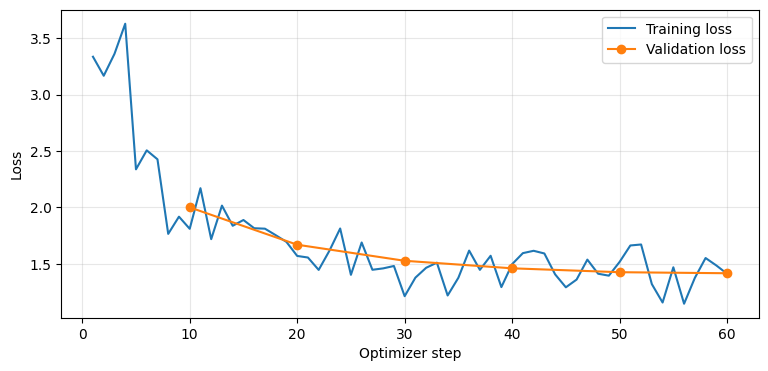

,step,eval_loss
10,10,2.000398
21,20,1.669297
32,30,1.526837
43,40,1.460079
54,50,1.425591
65,60,1.416403


In [ ]:
trainer_stats = trainer.train()

import pandas as pd
import matplotlib.pyplot as plt
loss_history = pd.DataFrame(trainer.state.log_history)
train_loss = loss_history.dropna(subset=["loss"])[["step", "loss"]]
val_loss = loss_history.dropna(subset=["eval_loss"])[["step", "eval_loss"]]
plt.figure(figsize=(9, 4))
plt.plot(train_loss.step, train_loss.loss, label="Training loss")
plt.plot(val_loss.step, val_loss.eval_loss, "o-", label="Validation loss")
plt.xlabel("Optimizer step")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()
display(val_loss)

In [ ]:
# @title Show final memory and time stats
used_memory = round(torch.cuda.max_memory_reserved() / 1024 / 1024 / 1024, 3)
used_memory_for_lora = round(used_memory - start_gpu_memory, 3)
used_percentage = round(used_memory / max_memory * 100, 3)
lora_percentage = round(used_memory_for_lora / max_memory * 100, 3)
print(f"{trainer_stats.metrics['train_runtime']} seconds used for training.")
print(
    f"{round(trainer_stats.metrics['train_runtime']/60, 2)} minutes used for training."
)
print(f"Peak reserved memory = {used_memory} GB.")
print(f"Peak reserved memory for training = {used_memory_for_lora} GB.")
print(f"Peak reserved memory % of max memory = {used_percentage} %.")
print(f"Peak reserved memory for training % of max memory = {lora_percentage} %.")

415.184 seconds used for training.
6.92 minutes used for training.
Peak reserved memory = 5.08 GB.
Peak reserved memory for training = 0.562 GB.
Peak reserved memory % of max memory = 34.883 %.
Peak reserved memory for training % of max memory = 3.859 %.


<a name="Inference"></a>
### Inference
Let's run the model via Unsloth native inference! According to the `Gemma-3` team, the recommended settings for inference are `temperature = 1.0, top_p = 0.95, top_k = 64`

In [ ]:
from unsloth.chat_templates import get_chat_template
tokenizer = get_chat_template(
    tokenizer,
    chat_template = "gemma-3",
)
messages = [{
    "role": "user",
    "content": [{
        "type" : "text",
        "text" : "ទៅមុខ១០មហើយបត់ឆ្វេង",
    }]
}]
text = tokenizer.apply_chat_template(
    messages,
    tokenize = False,
    add_generation_prompt = True, # Must add for generation
)
outputs = model.generate(
    **getattr(tokenizer, "tokenizer", tokenizer)([text], return_tensors = "pt", add_special_tokens=False).to("cuda"),
    max_new_tokens = 64, # Increase for longer outputs!
    # Recommended Gemma-3 settings!
    temperature = 1.0, top_p = 0.95, top_k = 64,
)
getattr(tokenizer, "tokenizer", tokenizer).batch_decode(outputs, skip_special_tokens=True)

['user\nទៅមុខ១០មហើយបត់ឆ្វេង\nmodel\nទៅមុខ ១០ មហើយបត់ឆ្វេង\\n']

 You can also use a `TextStreamer` for continuous inference - so you can see the generation token by token, instead of waiting the whole time!

In [ ]:
messages = [{
    "role": "user",
    "content": [{"type" : "text", "text" : "ទៅមុខ១០ម",}]
}]
text = tokenizer.apply_chat_template(
    messages,
    tokenize = False,
    add_generation_prompt = True, # Must add for generation
)

from transformers import TextStreamer
_ = model.generate(
    **getattr(tokenizer, "tokenizer", tokenizer)([text], return_tensors = "pt", add_special_tokens=False).to("cuda"),
    max_new_tokens = 64, # Increase for longer outputs!
    # Recommended Gemma-3 settings!
    temperature = 1.0, top_p = 0.95, top_k = 64,
    streamer = TextStreamer(getattr(tokenizer, "tokenizer", tokenizer), skip_prompt = True),
)

សូមទទួល។<end_of_turn>


<a name="Save"></a>
### Saving, loading finetuned models
To save the final model as LoRA adapters, either use Huggingface's `push_to_hub` for an online save or `save_pretrained` for a local save.

**[NOTE]** This ONLY saves the LoRA adapters, and not the full model. To save to 16bit or GGUF, scroll down!

In [ ]:
model.save_pretrained(str(DATA_PATH.parent / "gemma-3"))  # Local saving
tokenizer.save_pretrained(str(DATA_PATH.parent / "gemma-3"))
# model.push_to_hub("HF_ACCOUNT/gemma-3", token = "...") # Online saving
# tokenizer.push_to_hub("HF_ACCOUNT/gemma-3", token = "...") # Online saving

Unsloth: Restored added_tokens_decoder metadata in /content/drive/My Drive/ColabNotebooks/I5/ADV/gemma-3/tokenizer_config.json.
Unsloth: Preserved sentencepiece asset `tokenizer.model` in /content/drive/My Drive/ColabNotebooks/I5/ADV/gemma-3.


['/content/drive/My Drive/ColabNotebooks/I5/ADV/gemma-3/processor_config.json']

Now if you want to load the LoRA adapters we just saved for inference, set `False` to `True`:

In [ ]:
if False:
    from unsloth import FastModel
    model, tokenizer = FastModel.from_pretrained(
        model_name = str(DATA_PATH.parent / "gemma-3"), # YOUR MODEL YOU USED FOR TRAINING
        max_seq_length = 2048,
        load_in_4bit = True,
    )

messages = [{
    "role": "user",
    "content": [{"type" : "text", "text" : "បន្តទៅក្រោយ៩ម",}]
}]
text = tokenizer.apply_chat_template(
    messages,
    tokenize = False,
    add_generation_prompt = True, # Must add for generation
)

from transformers import TextStreamer
_ = model.generate(
    **getattr(tokenizer, "tokenizer", tokenizer)([text], return_tensors = "pt", add_special_tokens=False).to("cuda"),
    max_new_tokens = 64, # Increase for longer outputs!
    # Recommended Gemma-3 settings!
    temperature = 1.0, top_p = 0.95, top_k = 64,
    streamer = TextStreamer(getattr(tokenizer, "tokenizer", tokenizer), skip_prompt = True),
)

អេ ស៊ី ស៊ីរូ វីឌីជួញ (អេស៊ី សុខភាពខ្ពស់ មិនអានអំពី ការអនុញ្ញាតមិនអិយ) អេ ជួញ វីឌីជួញ (អេ សេវៃអ


### Saving to float16 for VLLM

We also support saving to `float16` directly for deployment! We save it in the folder `gemma-3-finetune`. Set `if False` to `if True` to let it run!

In [ ]:
if False: # Change to True to save finetune!
    model.save_pretrained_merged("gemma-3-finetune", tokenizer)

If you want to upload / push to your Hugging Face account, set `if False` to `if True` and add your Hugging Face token and upload location!

In [ ]:
if False: # Change to True to upload finetune
    model.push_to_hub_merged(
        "HF_ACCOUNT/gemma-3-finetune", tokenizer,
        token = "hf_..."
    )

In [ ]:
if False: # Change to True to save to GGUF
    model.save_pretrained_gguf(
        "gemma-3-finetune",
        quantization_type = "Q8_0", # For now only Q8_0, BF16, F16 supported
    )

Likewise, if you want to instead push to GGUF to your Hugging Face account, set `if False` to `if True` and add your Hugging Face token and upload location!

In [ ]:
if False: # Change to True to upload GGUF
    model.push_to_hub_gguf(
        "gemma-3-finetune",
        quantization_type = "Q8_0", # Only Q8_0, BF16, F16 supported
        repo_id = "HF_ACCOUNT/gemma-finetune-gguf",
        token = "hf_...",
    )

In [ ]:
import pandas as pd
from google.colab import drive

drive.mount('/content/drive')

loss_banking = pd.DataFrame({
    "step": [10, 20, 30, 40, 50, 60],
    "loss": [
        1.810252, 1.569814, 1.212971,
        1.496915, 1.516805, 1.411848
    ],
    "eval_loss": [
        2.000398, 1.669297, 1.526837,
        1.460079, 1.425591, 1.416403
    ]
})

loss_banking.to_csv(
    "/content/drive/My Drive/ColabNotebooks/I5/ADV/loss_banking.csv",
    index=False
)

display(loss_banking)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,step,loss,eval_loss
0,10,1.810252,2.000398
1,20,1.569814,1.669297
2,30,1.212971,1.526837
3,40,1.496915,1.460079
4,50,1.516805,1.425591
5,60,1.411848,1.416403
